# Подбор гиперпараметров и порога

Цель ноутбука:
1. Подобрать `C` для логистической регрессии и параметры случайного леса.
2. Сравнить модели по OOF-метрикам и прибыли.
3. Зафиксировать константы, которые потом читает Airflow (`airflow/jobs/config.py`).

Данные берутся напрямую из CSV (не из DWH), чтобы ноутбук был воспроизводим без Postgres.


In [ ]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold

# --- путь до airflow/, чтобы импортировать jobs.* ---
root = Path.cwd()
airflow_dir = root / "airflow" if (root / "airflow").exists() else root.parent / "airflow"
sys.path.append(str(airflow_dir))

from jobs.config import (
    FEATURES, SEED, LOGREG_PARAMS, FOREST_PARAMS, CALL_COST, DEPOSIT_VALUE,
)
from jobs.training import (
    fold_ids, make_pipeline, metrics_at, oof_proba, choose_threshold, campaign_profit
)



IMAGES = Path("../images")
IMAGES.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)

In [2]:
csv_path = Path("../../ML_HSE/bank_pet_project/bank-additional/bank-additional-full.csv")

raw = pd.read_csv(csv_path, sep=";")
raw = raw.rename(columns={
    "emp.var.rate": "emp_var_rate",
    "cons.price.idx": "cons_price_idx",
    "cons.conf.idx": "cons_conf_idx",
    "nr.employed": "nr_employed",
    "default": "credit_default",
})

raw["subscribed"] = raw["y"].astype(str).str.lower().isin(["yes", "1", "true"]).astype(int)
raw["never_contacted"] = (raw["pdays"] == 999).astype(int)
raw.loc[raw["pdays"] == 999, "pdays"] = pd.NA

x = raw[FEATURES]
y = raw["subscribed"].astype(int).to_numpy()

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = fold_ids(cv, x, y)

print(f"x: {x.shape}, y: {y.shape}, доля yes: {y.mean():.3f}")

x: (41188, 17), y: (41188,), доля yes: 0.113


In [3]:
def search_table(search: GridSearchCV | RandomizedSearchCV):
    """Результаты поиска в читаемую таблицу, отсортированную по рангу."""
    df = pd.DataFrame(search.cv_results_)
    param_cols = [c for c in df.columns if c.startswith("param_")]
    cols = param_cols + ["mean_test_score", "std_test_score", "rank_test_score"]
    cols = [c for c in cols if c in df.columns]
    return df[cols].sort_values("rank_test_score").round(4)

In [4]:
logreg_search = GridSearchCV(
    make_pipeline(LogisticRegression(max_iter=2000, random_state=SEED)),
    {"clf__C": [0.01, 0.1, 1.0, 10.0, 100.0]},
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
)
logreg_search.fit(x, y)

logreg_oof = oof_proba(logreg_search.best_estimator_, x, y, cv)
logreg_threshold, logreg_profit_cv = choose_threshold(y, logreg_oof, folds)

# mean и std по фолдам
logreg_metrics = metrics_at(y, logreg_oof, folds, logreg_threshold, with_std=True)

print("Лучший C:", logreg_search.best_params_["clf__C"])
print(f"Порог по прибыли (OOF): {logreg_threshold:.2f}")
print(f"Средняя прибыль на фолд: ${logreg_metrics['profit']:.0f} "
      f"± ${logreg_metrics['profit_std']:.0f}")

Лучший C: 1.0
Порог по прибыли (OOF): 0.19
Средняя прибыль на фолд: $2786 ± $116


In [5]:
forest_search = RandomizedSearchCV(
    make_pipeline(
        RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=1),
    ),
    {
        "clf__max_depth": [8, 16, None],
        "clf__min_samples_leaf": [5, 20, 50],
        "clf__max_features": ["sqrt", 0.3],
    },
    n_iter=6,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
    random_state=SEED,
)
forest_search.fit(x, y)

forest_oof = oof_proba(forest_search.best_estimator_, x, y, cv)
forest_threshold, forest_profit_cv = choose_threshold(y, forest_oof, folds)

# mean и std по фолдам
forest_metrics = metrics_at(y, forest_oof, folds, forest_threshold, with_std=True)

print("Лучший лес:", forest_search.best_params_)
print(f"Порог по прибыли (OOF): {forest_threshold:.2f}")
print(f"Средняя прибыль на фолд: ${forest_metrics['profit']:.0f} "
      f"± ${forest_metrics['profit_std']:.0f}")

Лучший лес: {'clf__min_samples_leaf': 20, 'clf__max_features': 'sqrt', 'clf__max_depth': None}
Порог по прибыли (OOF): 0.18
Средняя прибыль на фолд: $2936 ± $127


## Результаты поиска гиперпараметров

Ниже — все комбинации, отсортированные по рангу (`rank_test_score`).
Метрика поиска — `average_precision` (PR-AUC): при дисбалансе ~11% она информативнее accuracy.

In [6]:
print("=== LogisticRegression: GridSearch по C ===")
display(search_table(logreg_search))

print("=== RandomForest: RandomizedSearch ===")
display(search_table(forest_search))

=== LogisticRegression: GridSearch по C ===


,param_clf__C,mean_test_score,std_test_score,rank_test_score
2,1.00,0.4462,0.0199,1
3,10.00,0.4462,0.0199,2
4,100.00,0.4461,0.0199,3
1,0.10,0.4461,0.0203,4
0,0.01,0.4455,0.0216,5


=== RandomForest: RandomizedSearch ===


,param_clf__min_samples_leaf,param_clf__max_features,param_clf__max_depth,mean_test_score,std_test_score,rank_test_score
5,20,sqrt,None,0.4663,0.0201,1
4,5,0.3,8,0.4658,0.0219,2
3,50,0.3,8,0.4627,0.0202,3
2,50,sqrt,16,0.4617,0.0203,4
0,5,sqrt,8,0.4611,0.0231,5
1,20,sqrt,8,0.4587,0.0219,6


In [12]:
rows = {}
for model, m, thr in [
    ("logreg",        logreg_metrics, logreg_threshold),
    ("random_forest", forest_metrics, forest_threshold),
]:
    rows[model] = {
        "threshold": f"{thr:.2f}",
        "profit":    f"{m['profit']:.0f} ± {m['profit_std']:.0f}",
        "roc_auc":   f"{m['roc_auc']:.3f} ± {m['roc_auc_std']:.3f}",
        "pr_auc":    f"{m['pr_auc']:.3f} ± {m['pr_auc_std']:.3f}",
        "precision": f"{m['precision']:.3f} ± {m['precision_std']:.3f}",
        "recall":    f"{m['recall']:.3f} ± {m['recall_std']:.3f}",
        "accuracy":  f"{m['accuracy']:.3f} ± {m['accuracy_std']:.3f}",
    }

metrics_df = pd.DataFrame(rows).T
metrics_df.index.name = "model"
display(metrics_df)

,threshold,profit,roc_auc,pr_auc,precision,recall,accuracy
model,,,,,,,
logreg,0.19,2786 ± 116,0.788 ± 0.006,0.446 ± 0.020,0.423 ± 0.013,0.570 ± 0.012,0.864 ± 0.004
random_forest,0.18,2936 ± 127,0.795 ± 0.007,0.466 ± 0.020,0.427 ± 0.013,0.595 ± 0.014,0.864 ± 0.004


## Baseline: порог 0.5

Прежде чем делать выводы, полезно понять **ценность подбора порога**.
Возьмём те же модели, но с дефолтным порогом 0.5 — так делает «наивный» ML-подход,
когда порог не подбирают под бизнес-задачу.

При пороге 0.5 модель зовёт только клиентов с вероятностью согласия > 50%.

In [11]:
# baseline: та же модель, но дефолтный порог 0.5
baseline_lr = metrics_at(y, logreg_oof, folds, threshold=0.5, with_std=True)
baseline_rf = metrics_at(y, forest_oof, folds, threshold=0.5, with_std=True)

print("=== LogReg ===")
print(f"  порог 0.50 (baseline): ${baseline_lr['profit']:.0f} ± ${baseline_lr['profit_std']:.0f}")
print(f"  порог {logreg_threshold:.2f} (подобран): ${logreg_metrics['profit']:.0f} ± ${logreg_metrics['profit_std']:.0f}")
print(f"  прирост: ${logreg_metrics['profit'] - baseline_lr['profit']:+.0f} на фолд")

print("=== RandomForest ===")
print(f"  порог 0.50 (baseline): ${baseline_rf['profit']:.0f} ± ${baseline_rf['profit_std']:.0f}")
print(f"  порог {forest_threshold:.2f} (подобран): ${forest_metrics['profit']:.0f} ± ${forest_metrics['profit_std']:.0f}")
print(f"  прирост: ${forest_metrics['profit'] - baseline_rf['profit']:+.0f} на фолд")

=== LogReg ===
  порог 0.50 (baseline): $1502 ± $183
  порог 0.19 (подобран): $2786 ± $116
  прирост: $+1284 на фолд
=== RandomForest ===
  порог 0.50 (baseline): $1337 ± $192
  порог 0.18 (подобран): $2936 ± $127
  прирост: $+1599 на фолд


**Вывод:** подбор порога по прибыли увеличивает прибыль
в 1.8–2.2 раза при той же модели и тех же предсказаниях. Меняется только
решение «звонить/не звонить», а не качество ранжирования — ROC-AUC и PR-AUC
у baseline и подобранного порога **одинаковые** (они не зависят от порога).

Именно поэтому в проекте порог подбирается по бизнес-метрике
`profit = 10·TP − 2·calls`, а не берётся дефолтный 0.5.

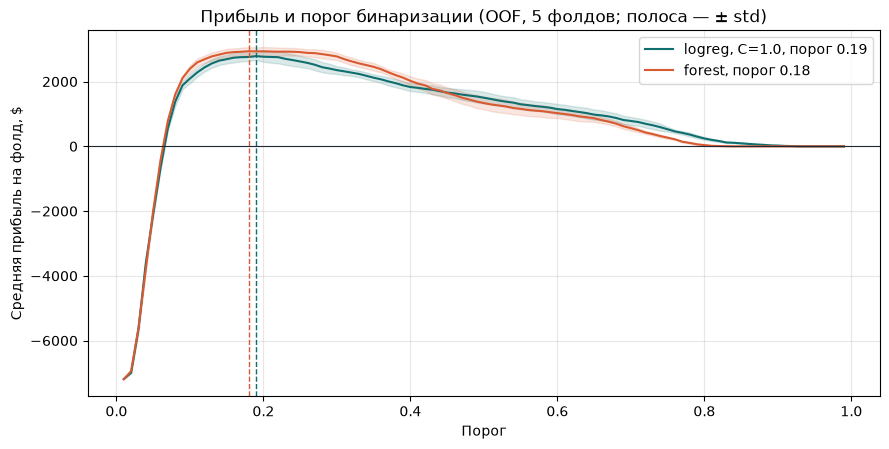

In [8]:
def threshold_curve(y, proba, folds, thresholds):
    """Средние по фолдам прибыль/расход/доход и std прибыли в зависимости от порога."""
    profits, expenses, revenues, profits_std = [], [], [], []
    for t in thresholds:
        per_fold_profit, per_fold_expense = [], []
        for fold in np.unique(folds):
            mask = folds == fold
            pred = (proba[mask] >= t).astype(int)
            tp = int((pred & (y[mask] == 1)).sum())
            calls = int(pred.sum())
            per_fold_profit.append(DEPOSIT_VALUE * tp - CALL_COST * calls)
            per_fold_expense.append(CALL_COST * calls)
        profits.append(np.mean(per_fold_profit))
        profits_std.append(np.std(per_fold_profit))
        expenses.append(np.mean(per_fold_expense))
        revenues.append(np.mean(per_fold_profit) + np.mean(per_fold_expense))
    return (np.array(profits), np.array(expenses), np.array(revenues),
            np.array(profits_std))

thresholds = np.round(np.arange(0.01, 1.0, 0.01), 2)

profit_lr, expense_lr, revenue_lr, profit_lr_std = threshold_curve(y, logreg_oof, folds, thresholds)
profit_rf, _,          _,          profit_rf_std = threshold_curve(y, forest_oof, folds, thresholds)

best_lr = thresholds[int(profit_lr.argmax())]
best_rf = thresholds[int(profit_rf.argmax())]

sign_change = np.where(np.diff(np.signbit(profit_lr)))[0]
breakeven_lr = thresholds[sign_change[0]] if len(sign_change) else None

fig1, ax1 = plt.subplots(figsize=(9, 4.6))

# logreg: линия + полоса ± std
ax1.plot(thresholds, profit_lr, color="#0F6E6E",
         label=f"logreg, C={logreg_search.best_params_['clf__C']}, порог {best_lr:.2f}")
ax1.fill_between(thresholds, profit_lr - profit_lr_std, profit_lr + profit_lr_std,
                 color="#0F6E6E", alpha=0.15)

# forest: линия + полоса ± std
ax1.plot(thresholds, profit_rf, color="#D85A30",
         label=f"forest, порог {best_rf:.2f}")
ax1.fill_between(thresholds, profit_rf - profit_rf_std, profit_rf + profit_rf_std,
                 color="#D85A30", alpha=0.15)

ax1.axvline(best_lr, color="#0F6E6E", linestyle="--", linewidth=1)
ax1.axvline(best_rf, color="#D85A30", linestyle="--", linewidth=1)
ax1.axhline(0, color="#1F2933", linewidth=0.8)
ax1.set_xlabel("Порог")
ax1.set_ylabel("Средняя прибыль на фолд, $")
ax1.set_title("Прибыль и порог бинаризации (OOF, 5 фолдов; полоса — ± std)")
ax1.legend(frameon=True)
ax1.grid(alpha=0.3)
fig1.tight_layout()
fig1.savefig("../images/threshold_curve.png", dpi=150, bbox_inches="tight")
plt.show()



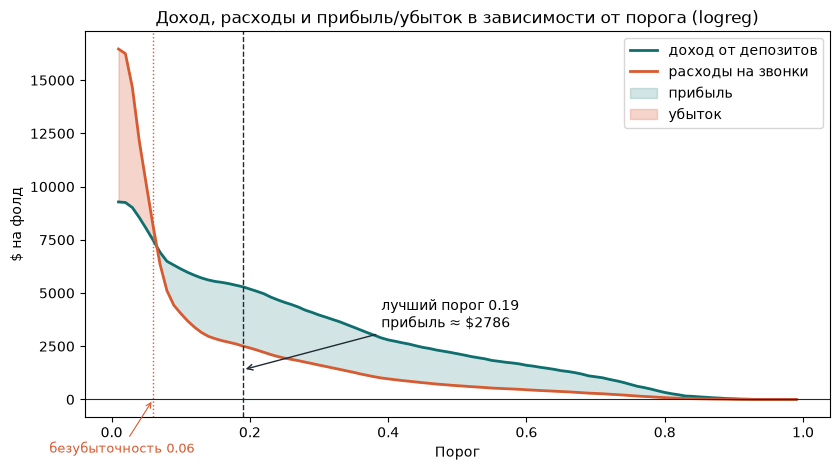

In [9]:

fig2, ax2 = plt.subplots(figsize=(8.5, 4.8))
ax2.plot(thresholds, revenue_lr, color="#0F6E6E", linewidth=2, label="доход от депозитов")
ax2.plot(thresholds, expense_lr, color="#D85A30", linewidth=2, label="расходы на звонки")
ax2.fill_between(thresholds, expense_lr, revenue_lr,
                 where=revenue_lr >= expense_lr, color="#0F6E6E", alpha=0.18, label="прибыль")
ax2.fill_between(thresholds, expense_lr, revenue_lr,
                 where=revenue_lr < expense_lr, color="#D85A30", alpha=0.25, label="убыток")
ax2.axhline(0, color="#1F2933", linewidth=0.8)
ax2.axvline(best_lr, color="#1F2933", linestyle="--", linewidth=1)
ax2.annotate(f"лучший порог {best_lr:.2f}\nприбыль ≈ ${profit_lr.max():.0f}",
             xy=(best_lr, profit_lr.max() / 2),
             xytext=(best_lr + 0.2, profit_lr.max() / 2 + 2000),
             arrowprops=dict(arrowstyle="->", color="#1F2933"))
if breakeven_lr is not None:
    ax2.axvline(breakeven_lr, color="#D85A30", linestyle=":", linewidth=1)
    ax2.annotate(f"безубыточность {breakeven_lr:.2f}",
                 xy=(breakeven_lr, 0),
                 xytext=(breakeven_lr - 0.15, -2500),
                 fontsize=9, color="#D85A30",
                 arrowprops=dict(arrowstyle="->", color="#D85A30", lw=0.8))
ax2.set_xlabel("Порог")
ax2.set_ylabel("$ на фолд")
ax2.set_title("Доход, расходы и прибыль/убыток в зависимости от порога (logreg)")
ax2.legend(frameon=True, loc="upper right")
fig2.tight_layout()
fig2.savefig("../images/threshold_curve_money.png", dpi=150, bbox_inches="tight")
plt.show()

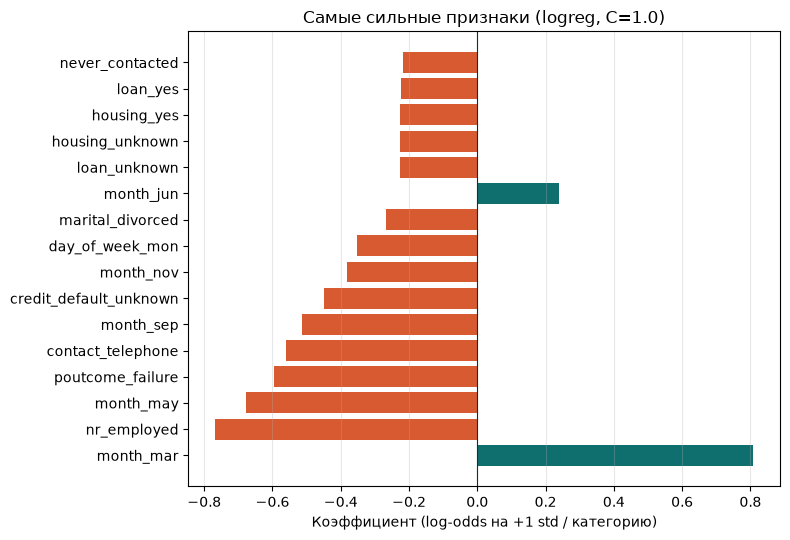

Топ-10 по модулю:
month_mar                 0.808
nr_employed              -0.768
month_may                -0.678
poutcome_failure         -0.596
contact_telephone        -0.560
month_sep                -0.513
credit_default_unknown   -0.448
month_nov                -0.380
day_of_week_mon          -0.352
marital_divorced         -0.266


In [10]:
# --- Важность признаков: коэффициенты logreg ---
best_lr = logreg_search.best_estimator_          
pre = best_lr.named_steps["pre"]
clf = best_lr.named_steps["clf"]

feature_names = pre.get_feature_names_out()
feature_names = [n.replace("num__", "").replace("cat__", "") for n in feature_names]

coef = pd.Series(clf.coef_[0], index=feature_names)

# 16 самых сильных по модулю (8 положительных + 8 отрицательных — по факту)
top = coef.reindex(coef.abs().sort_values(ascending=False).head(16).index)
#top = top.sort_values(key = np.abs)                           # для barh: снизу вверх

fig, ax = plt.subplots(figsize=(8, 5.5))
colors = ["#D85A30" if v < 0 else "#0F6E6E" for v in top]
ax.barh(top.index, top.to_numpy(), color=colors)
ax.axvline(0, color="#1F2933", linewidth=0.8)
ax.set_xlabel("Коэффициент (log-odds на +1 std / категорию)")
ax.set_title(f"Самые сильные признаки (logreg, C={clf.C})")
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig(IMAGES / "coefficients.png", dpi=150, bbox_inches="tight")
plt.show()

# краткий текстовый вывод для README
print("Топ-10 по модулю:")
print(top.reindex(top.abs().sort_values(ascending=False).head(10).index).round(3).to_string())